# Pickup-point analysis

**Question:** How customers and revenue split across pickup points.
1. Which pickup points generate the most revenue?
2. Which pickup points attract the most customers?
3. Where do our each segment customers shop?
4. Do pickup points with more customers necessarily generate more revenue?

## 1. Import libraries and the shared order functions

In [1]:
from pathlib import Path
import sys

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src.customer_analysis import load_basket_lines, aggregate_orders

from src.customer_analysis import segment_customers, summarize_pickup_points

In [17]:
load_basket_lines().head()

,order_id,user_id,order_datetime,pickup_point,ean_code,quantity,new_price,product_concept,sales
0,d22551a6-1c57-47f9-b003-4531cbf5bef6,0DKWGcJ8itd0AxqSldV9lI6p74l2,2025-01-18 08:34:52,b3233bd3323f1aee,8714100768990,2,1.2,soupe,2.4
1,d22551a6-1c57-47f9-b003-4531cbf5bef6,0DKWGcJ8itd0AxqSldV9lI6p74l2,2025-01-18 08:34:52,b3233bd3323f1aee,5414972130378,1,1.8,nouilles instantanées,1.8
2,d22551a6-1c57-47f9-b003-4531cbf5bef6,0DKWGcJ8itd0AxqSldV9lI6p74l2,2025-01-18 08:34:52,b3233bd3323f1aee,5400119591058,2,3.7,plat préparé de poisson,7.4
3,d22551a6-1c57-47f9-b003-4531cbf5bef6,0DKWGcJ8itd0AxqSldV9lI6p74l2,2025-01-18 08:34:52,b3233bd3323f1aee,5400119609517,1,1.8,tomate cerise,1.8
4,d22551a6-1c57-47f9-b003-4531cbf5bef6,0DKWGcJ8itd0AxqSldV9lI6p74l2,2025-01-18 08:34:52,b3233bd3323f1aee,5400119575829,1,3.9,tomate cerise,3.9


## 2. Load orders and reproduce the segmentation

- The source has one row per product line.
- Aggregate to one row per order before counting visits. 
- Provisional sales are `quantity*new_price`, assuming the price is per unit.
- Reuse the three RFM segments from the segmentation analysis.

### Create one row per order

In [19]:
lines = load_basket_lines()
orders = aggregate_orders(lines)

pd.Series({
    "Basket lines": len(lines),
    "Unique orders": orders["order_id"].nunique(),
    "Customers": orders["user_id"].nunique(),
    "Pickup points": orders["pickup_point"].nunique(),
}).to_frame("Count")

,Count
Basket lines,967415
Unique orders,141153
Customers,1000
Pickup points,24


In [25]:
customers, segment_profiles = segment_customers(orders)

In [26]:
customers

,user_id,segment,recency,frequency,monetary
0,0DKWGcJ8itd0AxqSldV9lI6p74l2,Active High-Value,1,198,3705.6
1,0DqeDKgxqzWNRGBys2FdA0FGmbs2,Less-Recent Moderate-Value,214,93,2052.1
2,0R9p4rL8nthxpaVa3LDlpeXNnrE3,Active High-Value,18,100,5182.8
3,0S023rB22zYRt1k1vbr5mkbJesW2,Active High-Value,1,146,6464.4
4,0Wys4DCHzwVaFYSCnuMqo347XY82,Long-Inactive Low-Value,266,1,41.5
...,...,...,...,...,...
995,zpH3BaUQidQeioD3YGIfXS4g55q1,Active High-Value,4,107,1419.7
996,zrpth5g2OIfLiKpUqwshs5Q8gLi2,Active High-Value,4,334,6519.5
997,zt6tudZOACVbqFGXtexsnMZzS8J2,Active High-Value,4,174,9842.2
998,zzUnL94WcyXs0m8beqk94swBM0v2,Active High-Value,3,144,5231.8


In [27]:
segment_profiles

,segment,customers,median_recency,median_frequency,median_monetary,total_monetary,customer_share_pct,revenue_share_pct
0,Active High-Value,629,3.0,147.0,3211.00,2340430.2,62.9,85.228622
1,Less-Recent Moderate-Value,229,49.0,91.0,1337.10,395162.3,22.9,14.390149
2,Long-Inactive Low-Value,142,239.5,2.0,38.35,10468.8,14.2,0.381230


Use 141153 orders as pickup-point analysis

In [29]:
lines.head()

,order_id,user_id,order_datetime,pickup_point,ean_code,quantity,new_price,product_concept,sales
0,d22551a6-1c57-47f9-b003-4531cbf5bef6,0DKWGcJ8itd0AxqSldV9lI6p74l2,2025-01-18 08:34:52,b3233bd3323f1aee,8714100768990,2,1.2,soupe,2.4
1,d22551a6-1c57-47f9-b003-4531cbf5bef6,0DKWGcJ8itd0AxqSldV9lI6p74l2,2025-01-18 08:34:52,b3233bd3323f1aee,5414972130378,1,1.8,nouilles instantanées,1.8
2,d22551a6-1c57-47f9-b003-4531cbf5bef6,0DKWGcJ8itd0AxqSldV9lI6p74l2,2025-01-18 08:34:52,b3233bd3323f1aee,5400119591058,2,3.7,plat préparé de poisson,7.4
3,d22551a6-1c57-47f9-b003-4531cbf5bef6,0DKWGcJ8itd0AxqSldV9lI6p74l2,2025-01-18 08:34:52,b3233bd3323f1aee,5400119609517,1,1.8,tomate cerise,1.8
4,d22551a6-1c57-47f9-b003-4531cbf5bef6,0DKWGcJ8itd0AxqSldV9lI6p74l2,2025-01-18 08:34:52,b3233bd3323f1aee,5400119575829,1,3.9,tomate cerise,3.9


In [28]:
#Aggregated orders based on order id
orders.head()

,order_id,user_id,order_datetime,pickup_point,sales
0,507d7f42-f679-41d4-9520-6cc289a5b625,zpH3BaUQidQeioD3YGIfXS4g55q1,2024-12-02 11:47:47,142edab1280b2246,17.5
1,5f06fee3-f271-4e03-acd4-9ba56d3b3388,JuF8r9dPBXO8h3M1K5bYYIw7N1r1,2024-12-02 12:23:01,2e815a32c23cc1e2,29.4
2,fcb89fa6-8d7c-41c3-87a9-9d9aa664c22d,dNoJq5Yx6uR8vZdcch3rjNpZuGv2,2024-12-02 13:08:50,142edab1280b2246,19.0
3,b0cb97de-7b7a-43e9-b2f4-3587c45fa13f,9HPiuvBf5GO83NRQy8TR8ftDl6O2,2024-12-02 14:20:22,88a117b70eadde69,31.3
4,e1484438-311e-495b-a713-e34d68256a40,QFyDDwTUIWfKzqOcCvXUCkcZhgm2,2024-12-02 16:26:17,b73fc63876e68b0b,3.5


## 3. Check whether a customer belongs to just one pickup point

In [30]:
# How many different pickup points each customer has used
points_per_customer = orders.groupby("user_id")["pickup_point"].nunique()

# How many unique customers visited each pickup point
customers_by_point = orders.groupby("pickup_point")["user_id"].nunique()

In [32]:
pd.Series({
    "Unique customers overall": points_per_customer.size,
    "Sum of distinct customers across points": customers_by_point.sum(),
    "Customers using more than one point": points_per_customer.gt(1).sum(),
}).to_frame("Count")

,Count
Unique customers overall,1000
Sum of distinct customers across points,1810
Customers using more than one point,438


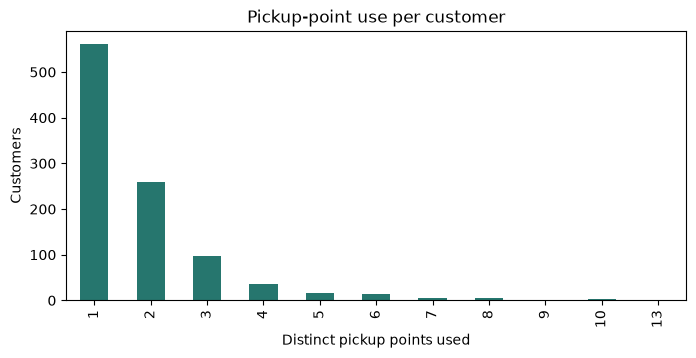

In [22]:
ax = points_per_customer.value_counts().sort_index().plot.bar(figsize=(8, 3.5), color="#26766e")
ax.set(xlabel="Distinct pickup points used", ylabel="Customers", title="Pickup-point use per customer")
plt.show()

Some customers shop at multiple pickup points, so they may be counted more than once.
- Count customers at every pickup point they visit to see how many customers each location attracts.
- Assign each customer to the location they visit most often, so each customer is counted only once.

## 4. Compare customers served with primary customers

To measure how many customers each location attracts, identify each customer's main location, and calculate sales correctly.
- Count a customer at every pickup point they visited, but only once per point.
- Assign each customer to the location where they placed the most orders.
- Choose the location they visited most recently. If still tied, use the pickup-point name to decide consistently. (eg. Point A & Point B choose Point A)
- Count revenue at the pickup point where the purchase actually happened, even if it's not the customer's primary point. (sales belong to the pickup point where the customer placed the order, not their primary pick up point) - To know how much revenue each pickup point actually generates.

In [37]:
# Find earliest and latest order dates in dataset
start_date = orders["order_datetime"].min().normalize()
end_date = orders["order_datetime"].max().normalize()
start_date, end_date

(Timestamp('2024-12-02 00:00:00'), Timestamp('2026-08-31 00:00:00'))

In [38]:
# All orders within the earliest & latest order time
period_orders = orders.loc[orders["order_datetime"].between(
    start_date, end_date + pd.Timedelta(days=1), inclusive="left"
)]
period_orders.head()

,order_id,user_id,order_datetime,pickup_point,sales
0,507d7f42-f679-41d4-9520-6cc289a5b625,zpH3BaUQidQeioD3YGIfXS4g55q1,2024-12-02 11:47:47,142edab1280b2246,17.5
1,5f06fee3-f271-4e03-acd4-9ba56d3b3388,JuF8r9dPBXO8h3M1K5bYYIw7N1r1,2024-12-02 12:23:01,2e815a32c23cc1e2,29.4
2,fcb89fa6-8d7c-41c3-87a9-9d9aa664c22d,dNoJq5Yx6uR8vZdcch3rjNpZuGv2,2024-12-02 13:08:50,142edab1280b2246,19.0
3,b0cb97de-7b7a-43e9-b2f4-3587c45fa13f,9HPiuvBf5GO83NRQy8TR8ftDl6O2,2024-12-02 14:20:22,88a117b70eadde69,31.3
4,e1484438-311e-495b-a713-e34d68256a40,QFyDDwTUIWfKzqOcCvXUCkcZhgm2,2024-12-02 16:26:17,b73fc63876e68b0b,3.5


In [43]:
pickup, segment_mix, primary = summarize_pickup_points(period_orders, customers)
pickup # How many customers, orders, and sales each pickup point has

,pickup_point,customers_served,orders,sales,primary_customers,primary_customer_share_pct,sales_share_pct
4,1a1c842a643d33ce,144,13300,249714.5,86,8.6,9.093552
2,142edab1280b2246,131,13387,237891.4,78,7.8,8.663004
6,2542941672fd21b8,110,11985,227996.0,79,7.9,8.302655
8,48db013424cf43ec,75,9365,203945.2,58,5.8,7.426826
3,18a21561ec87a9b3,67,6152,163466.0,47,4.7,5.952744
18,c725efe5d28aff6d,103,7416,152680.4,60,6.0,5.559978
15,b3233bd3323f1aee,113,7772,152577.8,63,6.3,5.556242
19,cbcb62162e461101,113,9885,152171.7,56,5.6,5.541453
7,2e815a32c23cc1e2,115,8119,150562.3,75,7.5,5.482846
12,88a117b70eadde69,78,6274,143818.2,46,4.6,5.237254


In [45]:
segment_mix #What customer segments shop at each pickup point and how much they spend

,pickup_point,segment,customers_served,sales
0,092a6887b4c84db6,Active High-Value,52,81740.2
1,092a6887b4c84db6,Less-Recent Moderate-Value,29,25509.5
2,092a6887b4c84db6,Long-Inactive Low-Value,10,514.2
3,0e7ecfc90eb1dd42,Active High-Value,75,125712.6
4,0e7ecfc90eb1dd42,Less-Recent Moderate-Value,19,13249.1
...,...,...,...,...
65,f4be5324d14ecdea,Less-Recent Moderate-Value,20,17777.9
66,f4be5324d14ecdea,Long-Inactive Low-Value,8,296.5
67,f8aa98ac894848ac,Active High-Value,53,103869.0
68,f8aa98ac894848ac,Less-Recent Moderate-Value,28,19193.1


In [46]:
primary #Each customer's most-used pickup point

,user_id,pickup_point,orders,last_visit,sales
613,L4ecRG20h3dLrDm1cdgOnITL82B3,48db013424cf43ec,1053,2026-08-29 12:55:27,7497.3
1035,YdLiL8QGTtXDHJizLpLCb3Vhdon2,142edab1280b2246,1004,2026-08-31 10:08:13,4737.0
1618,uMBBNaM3lzOjEztqpEgzYjDE4A72,142edab1280b2246,994,2026-08-31 11:59:32,10875.9
293,B0XvyIC5FyNdIcJXCZXARuBl1rv2,c725efe5d28aff6d,800,2026-08-31 13:32:55,2821.9
163,6A09PTHxF8d6B1kpTPFwoDS5jZX2,092a6887b4c84db6,746,2026-08-31 14:58:59,7572.9
...,...,...,...,...,...
804,QX0iXGt8OOZiUkTVd8ZRTmxEbTq1,f46feb23542f588a,1,2024-12-30 13:40:44,20.1
1748,xlRaMzVbhQd7lciU42CXyPQHncI2,b3233bd3323f1aee,1,2024-12-30 13:27:11,80.6
1736,xWfpkEr12BaepI6Pb67je56oXh12,c725efe5d28aff6d,1,2024-12-28 14:35:06,52.2
1002,XWtxkIKbE1WHcXES6ed6VprHjUy1,2e815a32c23cc1e2,1,2024-12-26 15:05:06,5.3


In [48]:
multi_point_customers = period_orders.groupby("user_id")["pickup_point"].nunique().gt(1).sum()
multi_point_customers # how many customers vistied multiple pickup points

np.int64(438)

In [53]:
# check that each customer appears only once
assert primary["user_id"].is_unique

In [54]:
# check that no customer is missing
assert len(primary) == period_orders["user_id"].nunique()

In [55]:
# check if total sales match
assert abs(pickup["sales"].sum() - period_orders["sales"].sum()) < 0.01

In [56]:
pickup.round(2)

,pickup_point,customers_served,orders,sales,primary_customers,primary_customer_share_pct,sales_share_pct
4,1a1c842a643d33ce,144,13300,249714.5,86,8.6,9.09
2,142edab1280b2246,131,13387,237891.4,78,7.8,8.66
6,2542941672fd21b8,110,11985,227996.0,79,7.9,8.30
8,48db013424cf43ec,75,9365,203945.2,58,5.8,7.43
3,18a21561ec87a9b3,67,6152,163466.0,47,4.7,5.95
18,c725efe5d28aff6d,103,7416,152680.4,60,6.0,5.56
15,b3233bd3323f1aee,113,7772,152577.8,63,6.3,5.56
19,cbcb62162e461101,113,9885,152171.7,56,5.6,5.54
7,2e815a32c23cc1e2,115,8119,150562.3,75,7.5,5.48
12,88a117b70eadde69,78,6274,143818.2,46,4.6,5.24


In [57]:
pickup['primary_customers'].sum()

np.int64(1000)

## 5. Check whether the highest-reach point also has the highest sales

Rank locations separately by customers served and by provisional sales. Marketing and sales can care about different locations. Basically, compare 2 different rankings of 25 pickup point (Reach rank (serves the most unique customers), sales rank))

In [60]:
comparison = pickup.assign(
    reach_rank=pickup["customers_served"].rank(method="min", ascending=False).astype(int),
    sales_rank=pickup["sales"].rank(method="min", ascending=False).astype(int),
)

comparison

,pickup_point,customers_served,orders,sales,primary_customers,primary_customer_share_pct,sales_share_pct,reach_rank,sales_rank
4,1a1c842a643d33ce,144,13300,249714.5,86,8.6,9.093552,1,1
2,142edab1280b2246,131,13387,237891.4,78,7.8,8.663004,2,2
6,2542941672fd21b8,110,11985,227996.0,79,7.9,8.302655,6,3
8,48db013424cf43ec,75,9365,203945.2,58,5.8,7.426826,14,4
3,18a21561ec87a9b3,67,6152,163466.0,47,4.7,5.952744,15,5
18,c725efe5d28aff6d,103,7416,152680.4,60,6.0,5.559978,8,6
15,b3233bd3323f1aee,113,7772,152577.8,63,6.3,5.556242,4,7
19,cbcb62162e461101,113,9885,152171.7,56,5.6,5.541453,4,8
7,2e815a32c23cc1e2,115,8119,150562.3,75,7.5,5.482846,3,9
12,88a117b70eadde69,78,6274,143818.2,46,4.6,5.237254,12,10


In [58]:
comparison.loc[
    comparison["reach_rank"].le(5) | comparison["sales_rank"].le(5),
    ["pickup_point", "reach_rank", "sales_rank", "customers_served", "sales_share_pct"],
].round(2)

,pickup_point,reach_rank,sales_rank,customers_served,sales_share_pct
4,1a1c842a643d33ce,1,1,144,9.09
2,142edab1280b2246,2,2,131,8.66
6,2542941672fd21b8,6,3,110,8.30
8,48db013424cf43ec,14,4,75,7.43
3,18a21561ec87a9b3,15,5,67,5.95
15,b3233bd3323f1aee,4,7,113,5.56
19,cbcb62162e461101,4,8,113,5.54
7,2e815a32c23cc1e2,3,9,115,5.48


Highest reach point also has the highest sales.
Customer reach and sales rankings are not always the same.

Marketing prioritize pickup points with high customer reach because they interact with more unique customers. 
- Do something that focus on reaching customers, eg. promote new product to more existing customers, promotional campaign etc)

Sales and operations prioritize pickup points with high revenue because they contribute more to business performance. 
- Study sales pattern and plan capacity (eg. ensure sufficient stocks/staff etc)

## 6. Compare the highest-sales pickup points

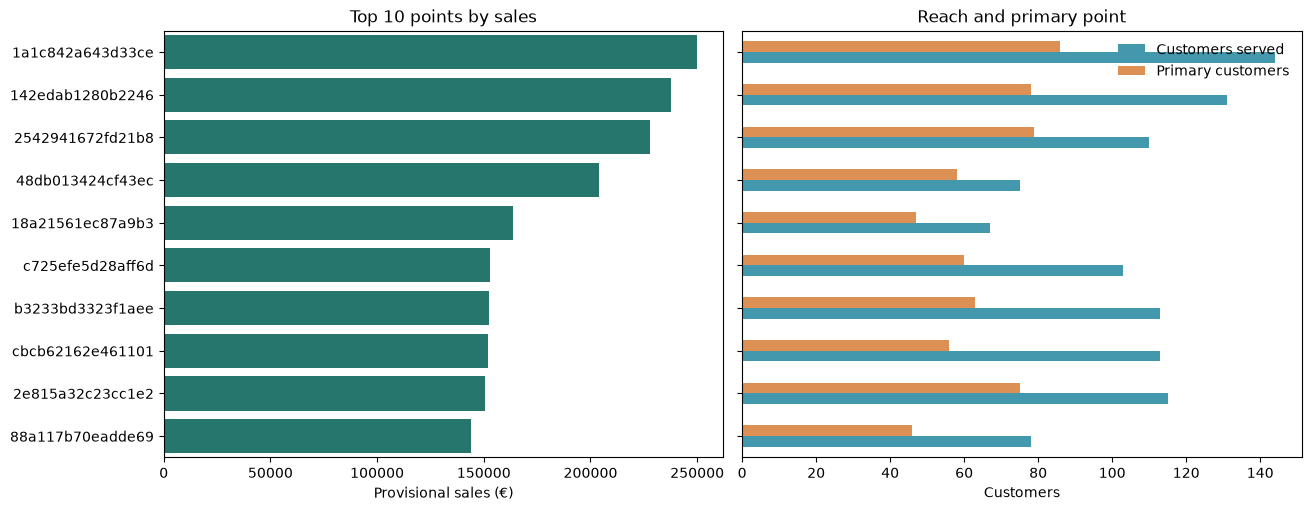

In [61]:
# Select Top 10 Pickup points
top_points = pickup.head(10).sort_values("sales")

# Create 2 charts side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True, layout="constrained")

# Sales by pickup point
axes[0].barh(top_points["pickup_point"], top_points["sales"], color="#26766e")
axes[0].set(xlabel="Provisional sales (€)", title="Top 10 points by sales")
axes[0].ticklabel_format(style="plain", axis="x")

#Customer ser
top_points.set_index("pickup_point")[["customers_served", "primary_customers"]].rename(
    columns={"customers_served": "Customers served", "primary_customers": "Primary customers"}
).plot.barh(ax=axes[1], color=["#4498ae", "#dd9054"])
axes[1].set(xlabel="Customers", ylabel="", title="Reach and primary point")
axes[1].legend(frameon=False)
plt.show()

## 7. Visualize customer segments by pickup point

The stacked bars count distinct customers at each point. Customers who visited several points can appear in several bars. Use this chart to identify points that serve a target segment.

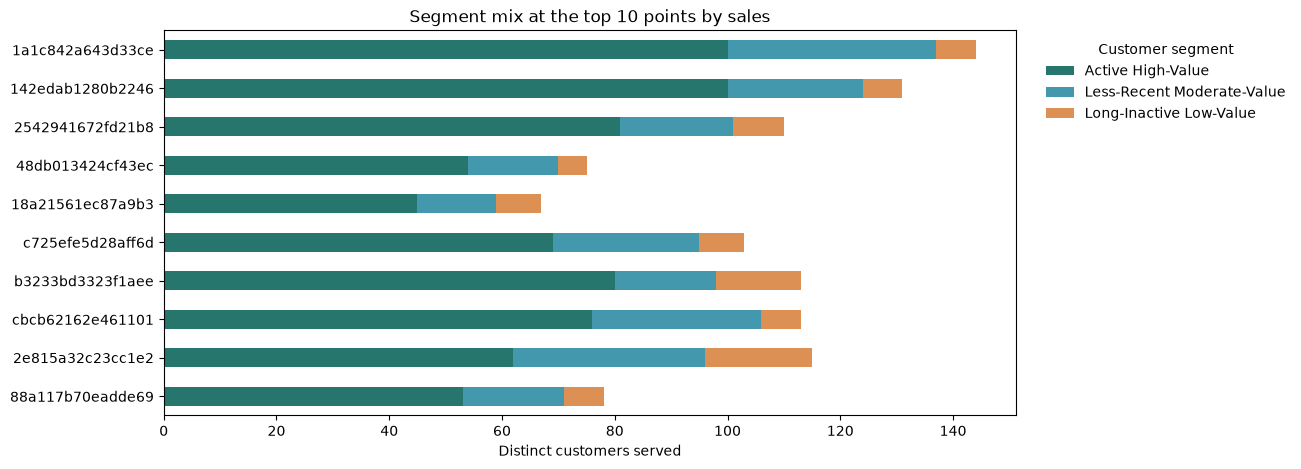

In [10]:
mix_table = segment_mix.pivot(index="pickup_point", columns="segment", values="customers_served")
mix_table = mix_table.reindex(top_points["pickup_point"]).fillna(0)
ax = mix_table.plot.barh(stacked=True, figsize=(11, 5), color=["#26766e", "#4498ae", "#dd9054"])
ax.set(xlabel="Distinct customers served", ylabel="", title="Segment mix at the top 10 points by sales")
ax.legend(title="Customer segment", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.show()

## 8. What each customer segment buys

The table shows how many customers are in each segment and how much they spent. 
\
pickup point = `None` for the overall view, or enter a pickup-point ID to see both tables for that location.

In [74]:
from importlib import reload
import src.customer_analysis as customer_analysis

customer_analysis = reload(customer_analysis)
selected_pickup = '1a1c842a643d33ce' #None for overall

segment_statistics = customer_analysis.summarize_segment_statistics(
    period_orders, customers, end_date, start_date=start_date
)
if selected_pickup is None:
    segment_view = segment_statistics["scope"].eq("all")
else:
    segment_view = segment_statistics["pickup_point"].eq(selected_pickup)

segment_statistics.loc[segment_view, [
    "segment", "num_customers", "customer_share_pct", "provisional_sales",
]].round(2)

,segment,num_customers,customer_share_pct,provisional_sales
15,Active High-Value,100,69.44,215920.9
16,Less-Recent Moderate-Value,37,25.69,33385.6
17,Long-Inactive Low-Value,7,4.86,408.0


### Which products did they buy?

Count how many different customers bought each product concept and show the top 10 per segment. \
Concept groups similar items, such as different brands of mozzarella.

In [73]:
product_rankings = customer_analysis.summarize_top_products(
    lines, customers, end_date, start_date=start_date
)
if selected_pickup is None:
    product_view = product_rankings["scope"].eq("all")
else:
    product_view = product_rankings["pickup_point"].eq(selected_pickup)

display(product_rankings.loc[
    product_view & product_rankings["product_level"].eq("concept"),
    ["segment", "rank", "product_concept", "num_customers"],
])

,segment,rank,product_concept,num_customers
150,Active High-Value,1,oeuf,76
151,Active High-Value,2,salade,69
152,Active High-Value,3,biscuits,68
153,Active High-Value,4,pomme de terre,66
154,Active High-Value,5,mozzarella,66
155,Active High-Value,6,saumon fumé,63
156,Active High-Value,7,banane,62
157,Active High-Value,8,tomate cerise,62
158,Active High-Value,9,mélange de légumes frais,61
159,Active High-Value,10,filet de poulet nature,61


## 9. Key Findings

- Multiple pickup-point usage: 438 out of 1,000 customers (43.8%) used more than one pickup point.

- Customer counting: Two measures were used to avoid double-counting customers:

    - customers_served: Number of unique customers who used each pickup point.
    
    - primary_customers: Number of customers who used that pickup point most frequently.

- Sales attribution: Sales were assigned to the pickup point where each order occurred, regardless of the customer's primary pickup point.

- Highest customer reach and sales: Pickup point 1a1c842a643d33ce ranked first in both, serving 144 customers and generating €249,714.50 (9.09% of total sales).

- High sales despite lower reach: Pickup point 48db013424cf43ec ranked 14th in customer reach but 4th in sales, generating €203,945.20 from 75 customers.

- High reach but lower sales ranking: Pickup point 2e815a32c23cc1e2 ranked 3rd in customer reach (115 customers) but 9th in sales (€150,562.30).

- Customer segment contribution: At pickup point 092a6887b4c84db6, Active High-Value customers contributed €81,740.20, compared with €25,509.50 from Less-Recent Moderate-Value customers and €514.20 from Long-Inactive Low-Value customers.

- Customer reach and revenue performance are not always proportional.

- Some pickup points generate high sales despite serving fewer customers.

- Pickup-point performance are evaluated using customer reach, primary customer counts, order volume, sales, and customer segment composition together.